# POI Log Transformation Sensitivity Test

## Overview

This notebook tests one methodological choice used in both the Opportunity Layer and the Industry component: whether applying a logarithmic transformation to POI counts before normalisation materially changes the final POI probability distribution.

## 1. Import Libraries and Set Up Paths

In [1]:
# AI assistance: OpenAI Codex
# Prompt summary: Import the required libraries and locate the project root robustly.

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)


def find_project_root(start_path=None):
    """Find the repository root from the current working directory."""
    start = Path.cwd() if start_path is None else Path(start_path)

    for Associated in [start, *start.parents]:
        if (
            Associated.joinpath("ontology", "TRIP_PURPOSE_TO_POI_MAPPING.py").exists()
            and Associated.joinpath("ontology", "INDUSTRY_TO_POI_MAPPING.py").exists()
            and Associated.joinpath("data", "poi").exists()
        ):
            return Associated

    raise FileNotFoundError(
        "Could not locate the project root containing the ontologies and POI data."
    )


project_root = find_project_root()

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

input_path = (
    project_root
    / "data"
    / "poi"
    / "processed"
    / "manchester"
    / "District_manchester_poi_counts.xlsx"
)
validation_output_dir = (
    project_root
    / "output"
    / "validation"
    / "poi_log_transformation_sensitivity_test"
)
validation_output_dir.mkdir(parents=True, exist_ok=True)

print(f"Project root: {project_root}")
print(f"Input file: {input_path}")
print(f"Validation output directory: {validation_output_dir}")

Project root: c:\Users\user\OneDrive - University of Stirling\Desktop\dissertation\mobility-modelling-framework
Input file: c:\Users\user\OneDrive - University of Stirling\Desktop\dissertation\mobility-modelling-framework\data\poi\processed\manchester\District_manchester_poi_counts.xlsx
Validation output directory: c:\Users\user\OneDrive - University of Stirling\Desktop\dissertation\mobility-modelling-framework\output\validation\poi_log_transformation_sensitivity_test


## 2. Load POI Counts and Framework Mapping Ontologies

In [2]:
# AI assistance: OpenAI Codex
# Prompt summary: Load the POI counts and the Opportunity and Industry mapping ontologies.

from ontology.INDUSTRY_TO_POI_MAPPING import INDUSTRY_TO_POI_MAPPING
from ontology.TRIP_PURPOSE_TO_POI_MAPPING import TRIP_PURPOSE_TO_POI_MAPPING

poi_counts = pd.read_excel(input_path)

required_columns = {"POI Category", "POI Count"}
missing_columns = required_columns.difference(poi_counts.columns)

assert not missing_columns, f"Missing required columns: {sorted(missing_columns)}"
assert not poi_counts["POI Category"].duplicated().any(), (
    "POI categories must be unique."
)
assert poi_counts["POI Count"].notna().all(), "POI counts contain missing values."
assert (poi_counts["POI Count"] >= 0).all(), "POI counts must be non-negative."

print(f"Loaded {len(poi_counts)} POI categories.")
display(poi_counts)

Loaded 10 POI categories.


,POI Category,POI Count
0,Accommodation,139
1,Education,618
2,Employment,6031
3,Food and Beverage,2731
4,Healthcare,942
5,Personal Services,1613
6,Public Services,2899
7,Recreation,1256
8,Retail,2856
9,Transport,3401


## 3. Select Mappings Affected by the Methodological Choice

The Opportunity Layer uses count-based Probabilitying for context-dependent mappings. The Industry component uses the same method when an industry maps to multiple POI categories. All single-category mappings receive a Probability of 1.0, while excluded mappings receive no POI allocation; neither can change when log-transformed counts are replaced by raw counts.

In [3]:
# AI assistance: OpenAI Codex
# Prompt summary: Identify every Opportunity and Industry mapping affected by log transformation.

context_mappings = (
    TRIP_PURPOSE_TO_POI_MAPPING.loc[
        TRIP_PURPOSE_TO_POI_MAPPING["Mapping Strategy"]
        .eq("Context-dependent Mapping")
    ]
    .copy()
    .reset_index(drop=True)
)

multi_category_industries = {
    industry: categories
    for industry, categories in INDUSTRY_TO_POI_MAPPING.items()
    if isinstance(categories, list) and len(categories) > 1
}

assert not context_mappings.empty, "No context-dependent Opportunity mappings were found."
assert multi_category_industries, "No multi-category Industry mappings were found."

context_rows = []

for _, mapping in context_mappings.iterrows():
    context_rows.append(
        {
            "Component": "Opportunity Layer",
            "Allocation Context": mapping["Framework Trip Purpose"],
            "POI Categories": mapping["POI Categories"],
        }
    )

for industry, categories in multi_category_industries.items():
    context_rows.append(
        {
            "Component": "Industry Component",
            "Allocation Context": industry,
            "POI Categories": categories,
        }
    )

sensitivity_contexts = pd.DataFrame(context_rows)

mapped_categories = {
    category
    for categories in sensitivity_contexts["POI Categories"]
    for category in categories
}
available_categories = set(poi_counts["POI Category"])
missing_categories = mapped_categories.difference(available_categories)

assert not missing_categories, (
    f"Mapped POI categories are missing from the input data: {sorted(missing_categories)}"
)

print(
    f"Sensitivity test includes {len(sensitivity_contexts)} affected mappings: "
    f"{len(context_mappings)} Opportunity and "
    f"{len(multi_category_industries)} Industry."
)
display(sensitivity_contexts)

Sensitivity test includes 3 affected mappings: 2 Opportunity and 1 Industry.


,Component,Allocation Context,POI Categories
0,Opportunity Layer,Personal Business,"[Healthcare, Public Services, Personal Service..."
1,Opportunity Layer,Other Escort,"[Employment, Retail, Healthcare, Personal Serv..."
2,Industry Component,I Accommodation and food service activities,"[Accommodation, Food and Beverage]"


## 4. Calculate Normalised Probability With and Without Log Transformation

In [4]:
# AI assistance: OpenAI Codex
# Prompt summary: Calculate final normalised probability using log-transformed and raw POI counts.


def build_sensitivity_comparison(mapping_df, counts_df):
    """Compare log-transformed and raw-count probability for each affected mapping."""
    count_lookup = counts_df.set_index("POI Category")["POI Count"]
    rows = []

    for _, mapping in mapping_df.iterrows():
        component = mapping["Component"]
        allocation_context = mapping["Allocation Context"]
        categories = mapping["POI Categories"]
        selected_counts = count_lookup.loc[categories].astype(float)

        log_values = np.log1p(selected_counts)
        log_probability = log_values / log_values.sum()
        raw_probability = selected_counts / selected_counts.sum()

        for category in categories:
            with_log = float(log_probability.loc[category])
            without_log = float(raw_probability.loc[category])

            rows.append(
                {
                    "Component": component,
                    "Allocation Context": allocation_context,
                    "POI Category": category,
                    "POI Count": int(selected_counts.loc[category]),
                    "With Log Transformation": with_log,
                    "Without Log Transformation": without_log,
                    "Difference (Without - With Log)": without_log - with_log,
                    "Absolute Difference": abs(without_log - with_log),
                }
            )

    return pd.DataFrame(rows)


comparison = build_sensitivity_comparison(sensitivity_contexts, poi_counts)

comparison_display = comparison.copy()
comparison_display[
    [
        "With Log Transformation",
        "Without Log Transformation",
        "Difference (Without - With Log)",
        "Absolute Difference",
    ]
] = comparison_display[
    [
        "With Log Transformation",
        "Without Log Transformation",
        "Difference (Without - With Log)",
        "Absolute Difference",
    ]
].round(4)

display(comparison_display)

,Component,Allocation Context,POI Category,POI Count,With Log Transformation,Without Log Transformation,Difference (Without - With Log),Absolute Difference
0,Opportunity Layer,Personal Business,Healthcare,942,0.1490,0.0609,-0.0881,0.0881
1,Opportunity Layer,Personal Business,Public Services,2899,0.1735,0.1874,0.0139,0.0139
2,Opportunity Layer,Personal Business,Personal Services,1613,0.1607,0.1043,-0.0565,0.0565
3,Opportunity Layer,Personal Business,Food and Beverage,2731,0.1722,0.1765,0.0044,0.0044
4,Opportunity Layer,Personal Business,Employment,6031,0.1894,0.3898,0.2004,0.2004
5,Opportunity Layer,Personal Business,Recreation,1256,0.1553,0.0812,-0.0741,0.0741
6,Opportunity Layer,Other Escort,Employment,6031,0.1479,0.3266,0.1787,0.1787
7,Opportunity Layer,Other Escort,Retail,2856,0.1352,0.1547,0.0195,0.0195
8,Opportunity Layer,Other Escort,Healthcare,942,0.1164,0.0510,-0.0653,0.0653
9,Opportunity Layer,Other Escort,Personal Services,1613,0.1255,0.0873,-0.0381,0.0381


### 4.1 Validation

The following checks confirm that both sets of probability are valid probability distributions and that the sensitivity results cover exactly the count-based, multi-category mappings defined by the Opportunity and Industry ontologies.

In [5]:
# AI assistance: OpenAI Codex
# Prompt summary: Validate both normalised distributions and the framework-wide comparison output.

Probability_columns = [
    "With Log Transformation",
    "Without Log Transformation",
]
group_columns = ["Component", "Allocation Context"]

for column in Probability_columns:
    assert np.isfinite(comparison[column]).all(), f"{column} contains non-finite values."
    assert comparison[column].between(0, 1).all(), (
        f"{column} contains probability outside [0, 1]."
    )

    Probability_sums = comparison.groupby(group_columns)[column].sum()
    assert np.allclose(Probability_sums.to_numpy(), 1.0), (
        f"{column} does not sum to 1 for every affected mapping."
    )

expected_pairs = {
    (row["Component"], row["Allocation Context"], category)
    for _, row in sensitivity_contexts.iterrows()
    for category in row["POI Categories"]
}
actual_pairs = set(
    comparison[["Component", "Allocation Context", "POI Category"]]
    .itertuples(index=False, name=None)
)

assert actual_pairs == expected_pairs, (
    "The comparison output does not exactly match the affected ontology mappings."
)
assert not comparison.duplicated(
    subset=["Component", "Allocation Context", "POI Category"]
).any(), "Duplicate mapping-category rows were found."

assert set(comparison.loc[
    comparison["Component"].eq("Industry Component"), "Allocation Context"
]) == set(multi_category_industries), (
    "The Industry comparison does not cover every multi-category Industry mapping."
)

print("All sensitivity-test validation checks passed.")
display(
    comparison.groupby(group_columns)[Probability_columns]
    .sum()
    .round(6)
)

All sensitivity-test validation checks passed.


With Log Transformation  \
Component          Allocation Context                                                     
Industry Component I Accommodation and food service activities                      1.0   
Opportunity Layer  Other Escort                                                     1.0   
                   Personal Business                                                1.0   

                                                                Without Log Transformation  
Component          Allocation Context                                                       
Industry Component I Accommodation and food service activities                         1.0  
Opportunity Layer  Other Escort                                                        1.0  
                   Personal Business                                                   1.0

## 5. Summary of Changes

In [6]:
# AI assistance: OpenAI Codex
# Prompt summary: Summarise the largest category-level changes for every affected mapping.

summary_rows = []

for (component, allocation_context), group in comparison.groupby(
    ["Component", "Allocation Context"], sort=False
):
    largest_increase = group.loc[
        group["Difference (Without - With Log)"].idxmax()
    ]
    largest_decrease = group.loc[
        group["Difference (Without - With Log)"].idxmin()
    ]

    summary_rows.append(
        {
            "Component": component,
            "Allocation Context": allocation_context,
            "Categories Compared": len(group),
            "Largest Increase Without Log": largest_increase["POI Category"],
            "Increase (percentage points)": (
                largest_increase["Difference (Without - With Log)"] * 100
            ),
            "Largest Decrease Without Log": largest_decrease["POI Category"],
            "Decrease (percentage points)": (
                largest_decrease["Difference (Without - With Log)"] * 100
            ),
            "Maximum Absolute Difference (percentage points)": (
                group["Absolute Difference"].max() * 100
            ),
        }
    )

summary = pd.DataFrame(summary_rows)

summary_display = summary.copy()
summary_display[
    [
        "Increase (percentage points)",
        "Decrease (percentage points)",
        "Maximum Absolute Difference (percentage points)",
    ]
] = summary_display[
    [
        "Increase (percentage points)",
        "Decrease (percentage points)",
        "Maximum Absolute Difference (percentage points)",
    ]
].round(2)

display(summary_display)

,Component,Allocation Context,Categories Compared,Largest Increase Without Log,Increase (percentage points),Largest Decrease Without Log,Decrease (percentage points),Maximum Absolute Difference (percentage points)
0,Opportunity Layer,Personal Business,6,Employment,20.04,Healthcare,-8.81,20.04
1,Opportunity Layer,Other Escort,8,Employment,17.87,Accommodation,-7.64,17.87
2,Industry Component,I Accommodation and food service activities,2,Food and Beverage,33.60,Accommodation,-33.60,33.60


## 6. Visual Comparison of Final Normalised Probability

Saved figure to: c:\Users\user\OneDrive - University of Stirling\Desktop\dissertation\mobility-modelling-framework\output\validation\poi_log_transformation_sensitivity_test\poi_probabilities_with_and_without_log_transformation.png


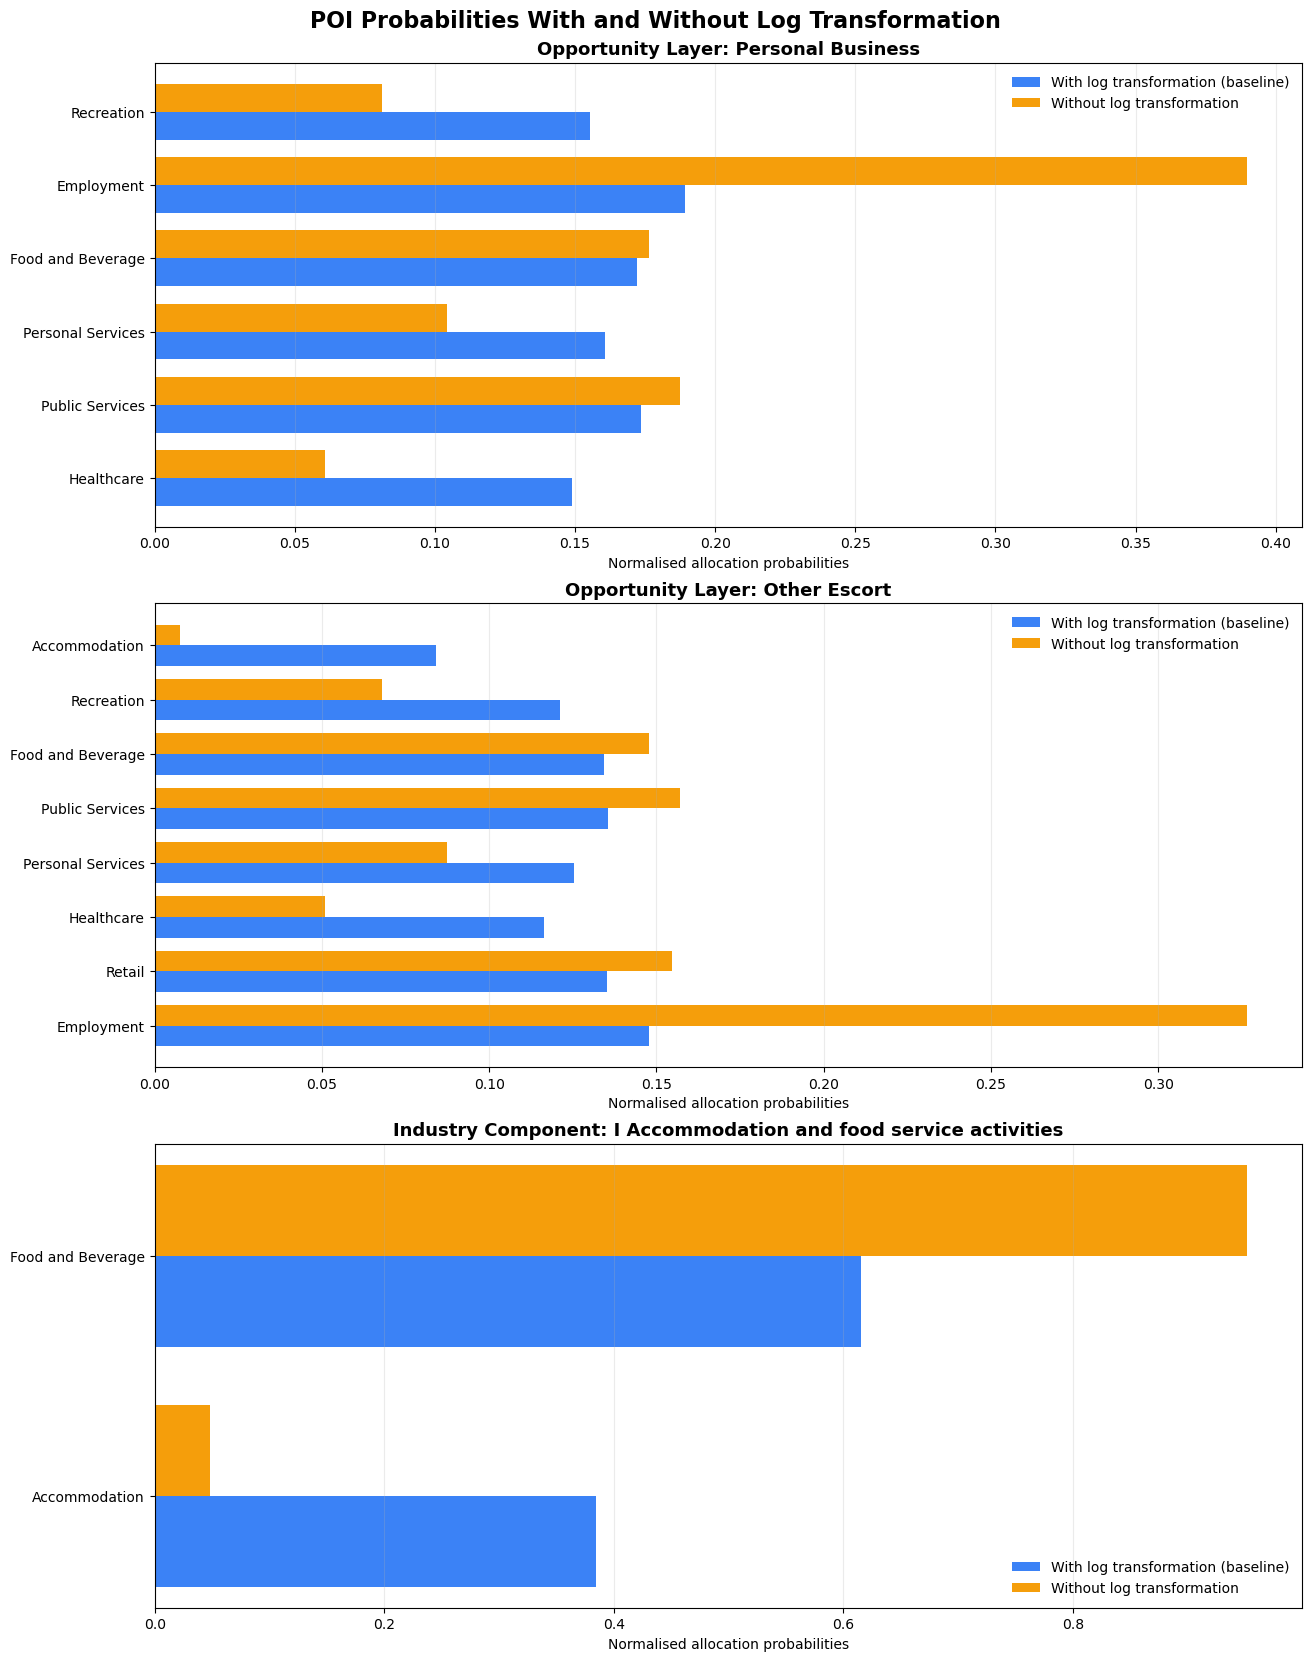

In [7]:
# AI assistance: OpenAI Codex
# Prompt summary: Plot final normalised probabilities with and without log transformation for all affected mappings.

contexts = list(
    sensitivity_contexts[["Component", "Allocation Context"]]
    .itertuples(index=False, name=None)
)
probability_fig, axes = plt.subplots(
    nrows=len(contexts),
    ncols=1,
    figsize=(13, 5.5 * len(contexts)),
    constrained_layout=True,
)

if len(contexts) == 1:
    axes = [axes]

bar_width = 0.38

for axis, (component, allocation_context) in zip(axes, contexts):
    plot_data = comparison.loc[
        comparison["Component"].eq(component)
        & comparison["Allocation Context"].eq(allocation_context)
    ].reset_index(drop=True)

    positions = np.arange(len(plot_data))

    axis.barh(
        positions - bar_width / 2,
        plot_data["With Log Transformation"],
        height=bar_width,
        label="With log transformation (baseline)",
        color="#3B82F6",
    )
    axis.barh(
        positions + bar_width / 2,
        plot_data["Without Log Transformation"],
        height=bar_width,
        label="Without log transformation",
        color="#F59E0B",
    )

    axis.set_title(
        f"{component}: {allocation_context}",
        fontsize=13,
        weight="bold",
    )
    axis.set_xlabel("Normalised allocation probabilities")
    axis.set_yticks(positions)
    axis.set_yticklabels(plot_data["POI Category"])
    axis.set_xlim(left=0)
    axis.grid(axis="x", alpha=0.25)
    axis.legend(frameon=False)

probability_fig.suptitle(
    "POI Probabilities With and Without Log Transformation",
    fontsize=16,
    weight="bold",
)
probabilities_figure_path = (
    validation_output_dir
    / "poi_probabilities_with_and_without_log_transformation.png"
)
# PNG EXPORT: save the complete normalised-probabilities comparison figure.
probability_fig.savefig(probabilities_figure_path, dpi=300, bbox_inches="tight")
print(f"Saved figure to: {probabilities_figure_path}")
plt.show()